# Homework 5 — DSCI 552

### Yuxin Yang 1505451394

In [1]:
# Embedded original UCI datasets
from pathlib import Path
import base64, io, zipfile
_DATA_ARCHIVE = """..."""
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_DATA_ARCHIVE))) as archive:
    Path('data').mkdir(exist_ok=True)
    for name in archive.namelist():
        Path('data', name).write_bytes(archive.read(name))
del _DATA_ARCHIVE


In [2]:
from pathlib import Path
import re, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, accuracy_score
from xgboost import XGBRegressor
import sklearn, xgboost
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error

SEED=42
DATA=Path('data')
FIG=Path('figures'); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
print('Python',sys.version.split()[0], '| sklearn',sklearn.__version__,'| XGBoost',xgboost.__version__)
def finish(name):
    plt.savefig(FIG/name, bbox_inches='tight', dpi=150)
    plt.show()


Python 3.13.5 | sklearn 1.8.0 | XGBoost 3.2.0


## 1(a–c). Acute Inflammations: data, full tree, and IF–THEN rules
The six predictors are temperature and five binary symptoms. The two diagnoses are bladder inflammation and nephritis of renal pelvis origin. The label-powerset encoding treats each observed pair of diagnoses as one class, preserving joint outcomes. A full classification tree is fitted to all 120 observations as requested.

Shape: (120, 8)


,count
"B=1, N=0",40
"B=0, N=1",31
"B=0, N=0",30
"B=1, N=1",19


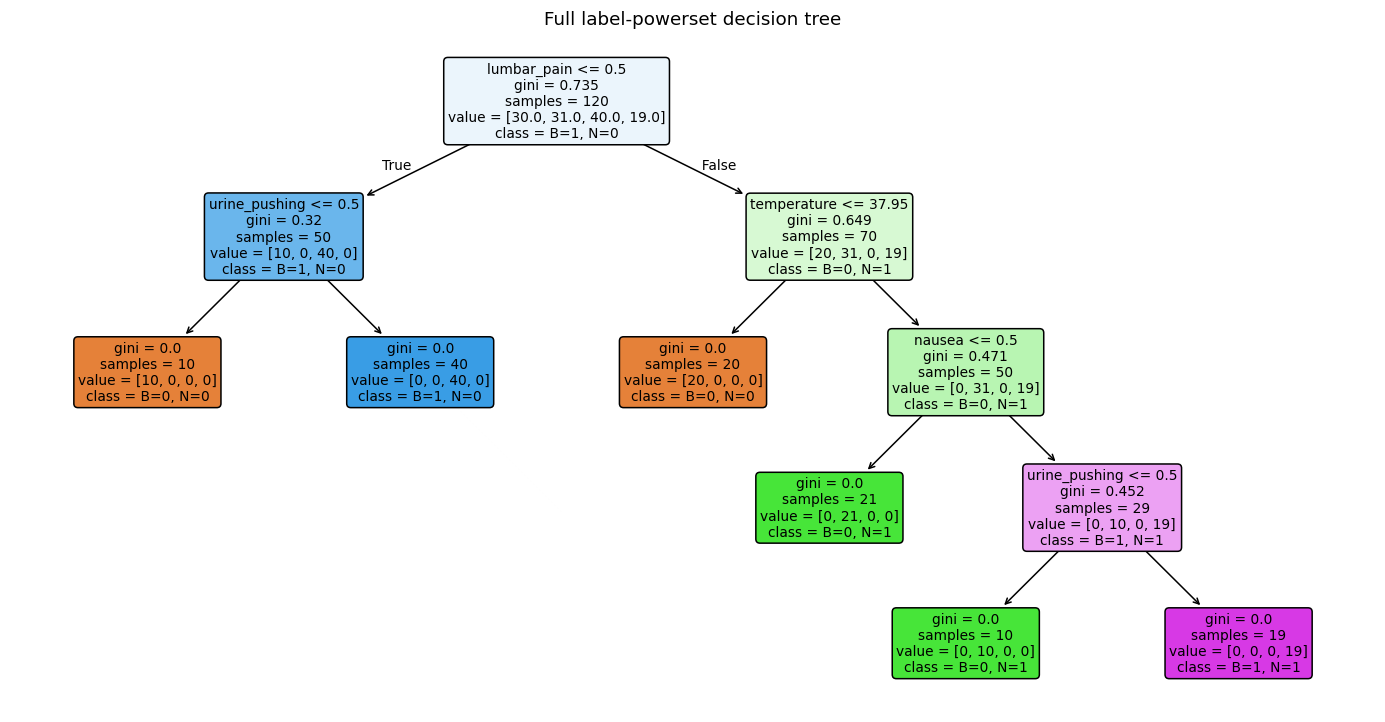

Training exact-pair accuracy: 1.0
B=bladder inflammation; N=nephritis; 1=yes, 0=no. Binary thresholds of 0.5 mean no/yes.
IF lumbar_pain <= 0.500 AND urine_pushing <= 0.500 THEN B=0, N=0 (n=10)
IF lumbar_pain <= 0.500 AND urine_pushing > 0.500 THEN B=1, N=0 (n=40)
IF lumbar_pain > 0.500 AND temperature <= 37.950 THEN B=0, N=0 (n=20)
IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea <= 0.500 THEN B=0, N=1 (n=21)
IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN B=0, N=1 (n=10)
IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing > 0.500 THEN B=1, N=1 (n=19)


In [3]:
acute_names=['temperature','nausea','lumbar_pain','urine_pushing','micturition_pain','urethra_burning','bladder','nephritis']
acute=pd.read_csv(DATA/'diagnosis.data',sep='\t',header=None,encoding='utf-16',decimal=',',names=acute_names)
for c in acute_names[1:]: acute[c]=acute[c].map({'yes':1,'no':0})
assert acute.shape==(120,8) and not acute.isna().any().any()
Xa=acute.iloc[:,:6]
ya=acute.apply(lambda r: f"B={int(r.bladder)}, N={int(r.nephritis)}",axis=1)
print('Shape:',acute.shape); display(ya.value_counts().rename('count').to_frame())
full=DecisionTreeClassifier(random_state=SEED).fit(Xa,ya)
plt.figure(figsize=(16,8)); plot_tree(full,feature_names=Xa.columns,class_names=full.classes_,filled=True,rounded=True,fontsize=9)
plt.title('Full label-powerset decision tree'); finish('full_tree.png')
print('Training exact-pair accuracy:',accuracy_score(ya,full.predict(Xa)))
def tree_rules(model):
    t=model.tree_; result=[]
    def walk(node,conditions):
        if t.children_left[node]==t.children_right[node]:
            label=model.classes_[np.argmax(t.value[node][0])]
            result.append('IF '+(' AND '.join(conditions) or 'TRUE')+' THEN '+label+f' (n={t.n_node_samples[node]})')
        else:
            f=Xa.columns[t.feature[node]]; v=t.threshold[node]
            walk(t.children_left[node], conditions+[f'{f} <= {v:.3f}'])
            walk(t.children_right[node],conditions+[f'{f} > {v:.3f}'])
    walk(0,[]); return result
print('B=bladder inflammation; N=nephritis; 1=yes, 0=no. Binary thresholds of 0.5 mean no/yes.')
print('\n'.join(tree_rules(full)))


## 1(d). Cost-complexity pruning
CART minimizes $R(T)+\alpha |\widetilde T|$, where $R(T)$ is sample-weighted leaf impurity and $|\widetilde T|$ is the number of leaves. I use five-fold stratified CV and the one-standard-error rule: choose the smallest tree whose mean exact-pair accuracy is at least the best mean minus its standard error. This makes “minimal” explicit: minimal among candidate subtrees meeting this predictive criterion.
The original tree has six leaves and achieves the highest cross-validation accuracy (0.9917). Further pruning reduces accuracy substantially. Therefore, the original tree is retained under the one-standard-error rule.

,alpha,leaves,depth,CV_accuracy,CV_SE,train_accuracy
0,0.000000,6,4,0.991667,0.008333,1.000000
1,0.098167,4,2,0.858333,0.025000,0.841667
2,0.133333,3,2,0.758333,0.033333,0.758333
3,0.182000,2,1,0.666667,0.029463,0.591667
4,0.222917,1,0,0.483333,0.061237,0.333333


Selected **alpha=0**, **6 leaves**, depth **4**; CV accuracy **0.9917**, training accuracy **1.0000**.

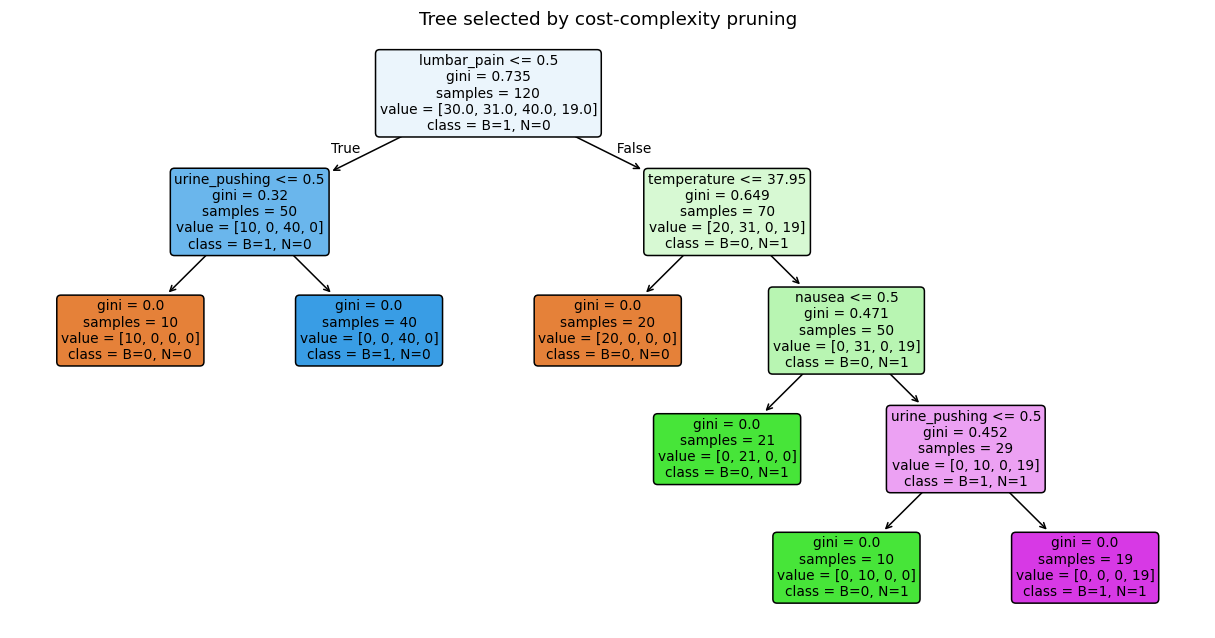

IF lumbar_pain <= 0.500 AND urine_pushing <= 0.500 THEN B=0, N=0 (n=10)
IF lumbar_pain <= 0.500 AND urine_pushing > 0.500 THEN B=1, N=0 (n=40)
IF lumbar_pain > 0.500 AND temperature <= 37.950 THEN B=0, N=0 (n=20)
IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea <= 0.500 THEN B=0, N=1 (n=21)
IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN B=0, N=1 (n=10)
IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing > 0.500 THEN B=1, N=1 (n=19)
The original tree is already compact; pruning it further fails the one-SE accuracy criterion.


In [4]:
path=full.cost_complexity_pruning_path(Xa,ya)
scv=StratifiedKFold(5,shuffle=True,random_state=SEED)
pr=[]
for a in np.unique(path.ccp_alphas):
    model=DecisionTreeClassifier(ccp_alpha=float(a),random_state=SEED)
    scores=cross_val_score(model,Xa,ya,cv=scv)
    model.fit(Xa,ya)
    pr.append([a,model.get_n_leaves(),model.get_depth(),scores.mean(),scores.std(ddof=1)/np.sqrt(5),model.score(Xa,ya)])
pr=pd.DataFrame(pr,columns=['alpha','leaves','depth','CV_accuracy','CV_SE','train_accuracy'])
best=pr.loc[pr.CV_accuracy.idxmax()]
chosen=pr[pr.CV_accuracy>=best.CV_accuracy-best.CV_SE].sort_values(['leaves','alpha'],ascending=[True,False]).iloc[0]
small=DecisionTreeClassifier(ccp_alpha=chosen.alpha,random_state=SEED).fit(Xa,ya)
display(pr); display(Markdown(f"Selected **alpha={chosen.alpha:.8g}**, **{small.get_n_leaves()} leaves**, depth **{small.get_depth()}**; CV accuracy **{chosen.CV_accuracy:.4f}**, training accuracy **{chosen.train_accuracy:.4f}**."))
plt.figure(figsize=(14,7)); plot_tree(small,feature_names=Xa.columns,class_names=small.classes_,filled=True,rounded=True,fontsize=9)
plt.title('Tree selected by cost-complexity pruning'); finish('pruned_tree.png')
print('\n'.join(tree_rules(small)))
if small.get_n_leaves()==full.get_n_leaves():
    print('The original tree is already compact; pruning it further fails the one-SE accuracy criterion.')


## 2(a–b). Communities and Crime: split and imputation
The response is `ViolentCrimesPerPop`. I discard `state`, `county`, `community`, `communityname`, and `fold`, which the data description identifies as nonpredictive. The first 1,495 rows form training data and the remaining 499 form test data, preserving original row order. Missing values (`?`) are replaced with training medians. During CV each imputer is refitted using only that fold's training rows.

In [5]:
names=re.findall(r'^@attribute\s+(\S+)',(DATA/'communities.names').read_text(),flags=re.M|re.I)
crime=pd.read_csv(DATA/'communities.data',header=None,names=names,na_values='?')
X=crime.drop(columns=['state','county','community','communityname','fold','ViolentCrimesPerPop']).astype(float)
y=crime['ViolentCrimesPerPop'].astype(float)
Xtr,Xte=X.iloc[:1495],X.iloc[1495:]
ytr,yte=y.iloc[:1495],y.iloc[1495:]
assert X.shape==(1994,122) and len(Xte)==499 and y.notna().all()
eda_imputer=SimpleImputer(strategy='median')
Xeda=pd.DataFrame(eda_imputer.fit_transform(Xtr),columns=X.columns,index=Xtr.index)
print('Predictors:',X.shape[1], '| train:',len(Xtr),'| test:',len(Xte))
print('Missing training cells:',int(Xtr.isna().sum().sum()))
display(Xtr.isna().sum().sort_values(ascending=False).head(25).rename('missing_train').to_frame())
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
folds=list(cv.split(Xtr))


Predictors: 122 | train: 1495 | test: 499
Missing training cells: 27633


,missing_train
PolicBudgPerPop,1256
PctPolicAsian,1256
LemasSwornFT,1256
LemasSwFTPerPop,1256
LemasSwFTFieldOps,1256
LemasSwFTFieldPerPop,1256
LemasTotalReq,1256
LemasTotReqPerPop,1256
PolicPerPop,1256
RacialMatchCommPol,1256


## 2(c). Feature correlation matrix
Pearson correlations are computed on the median-imputed training predictors. The saved high-resolution matrix includes all 122 names. Related population, income, housing, and policing measures form correlated groups; these motivate regularization and PCR.

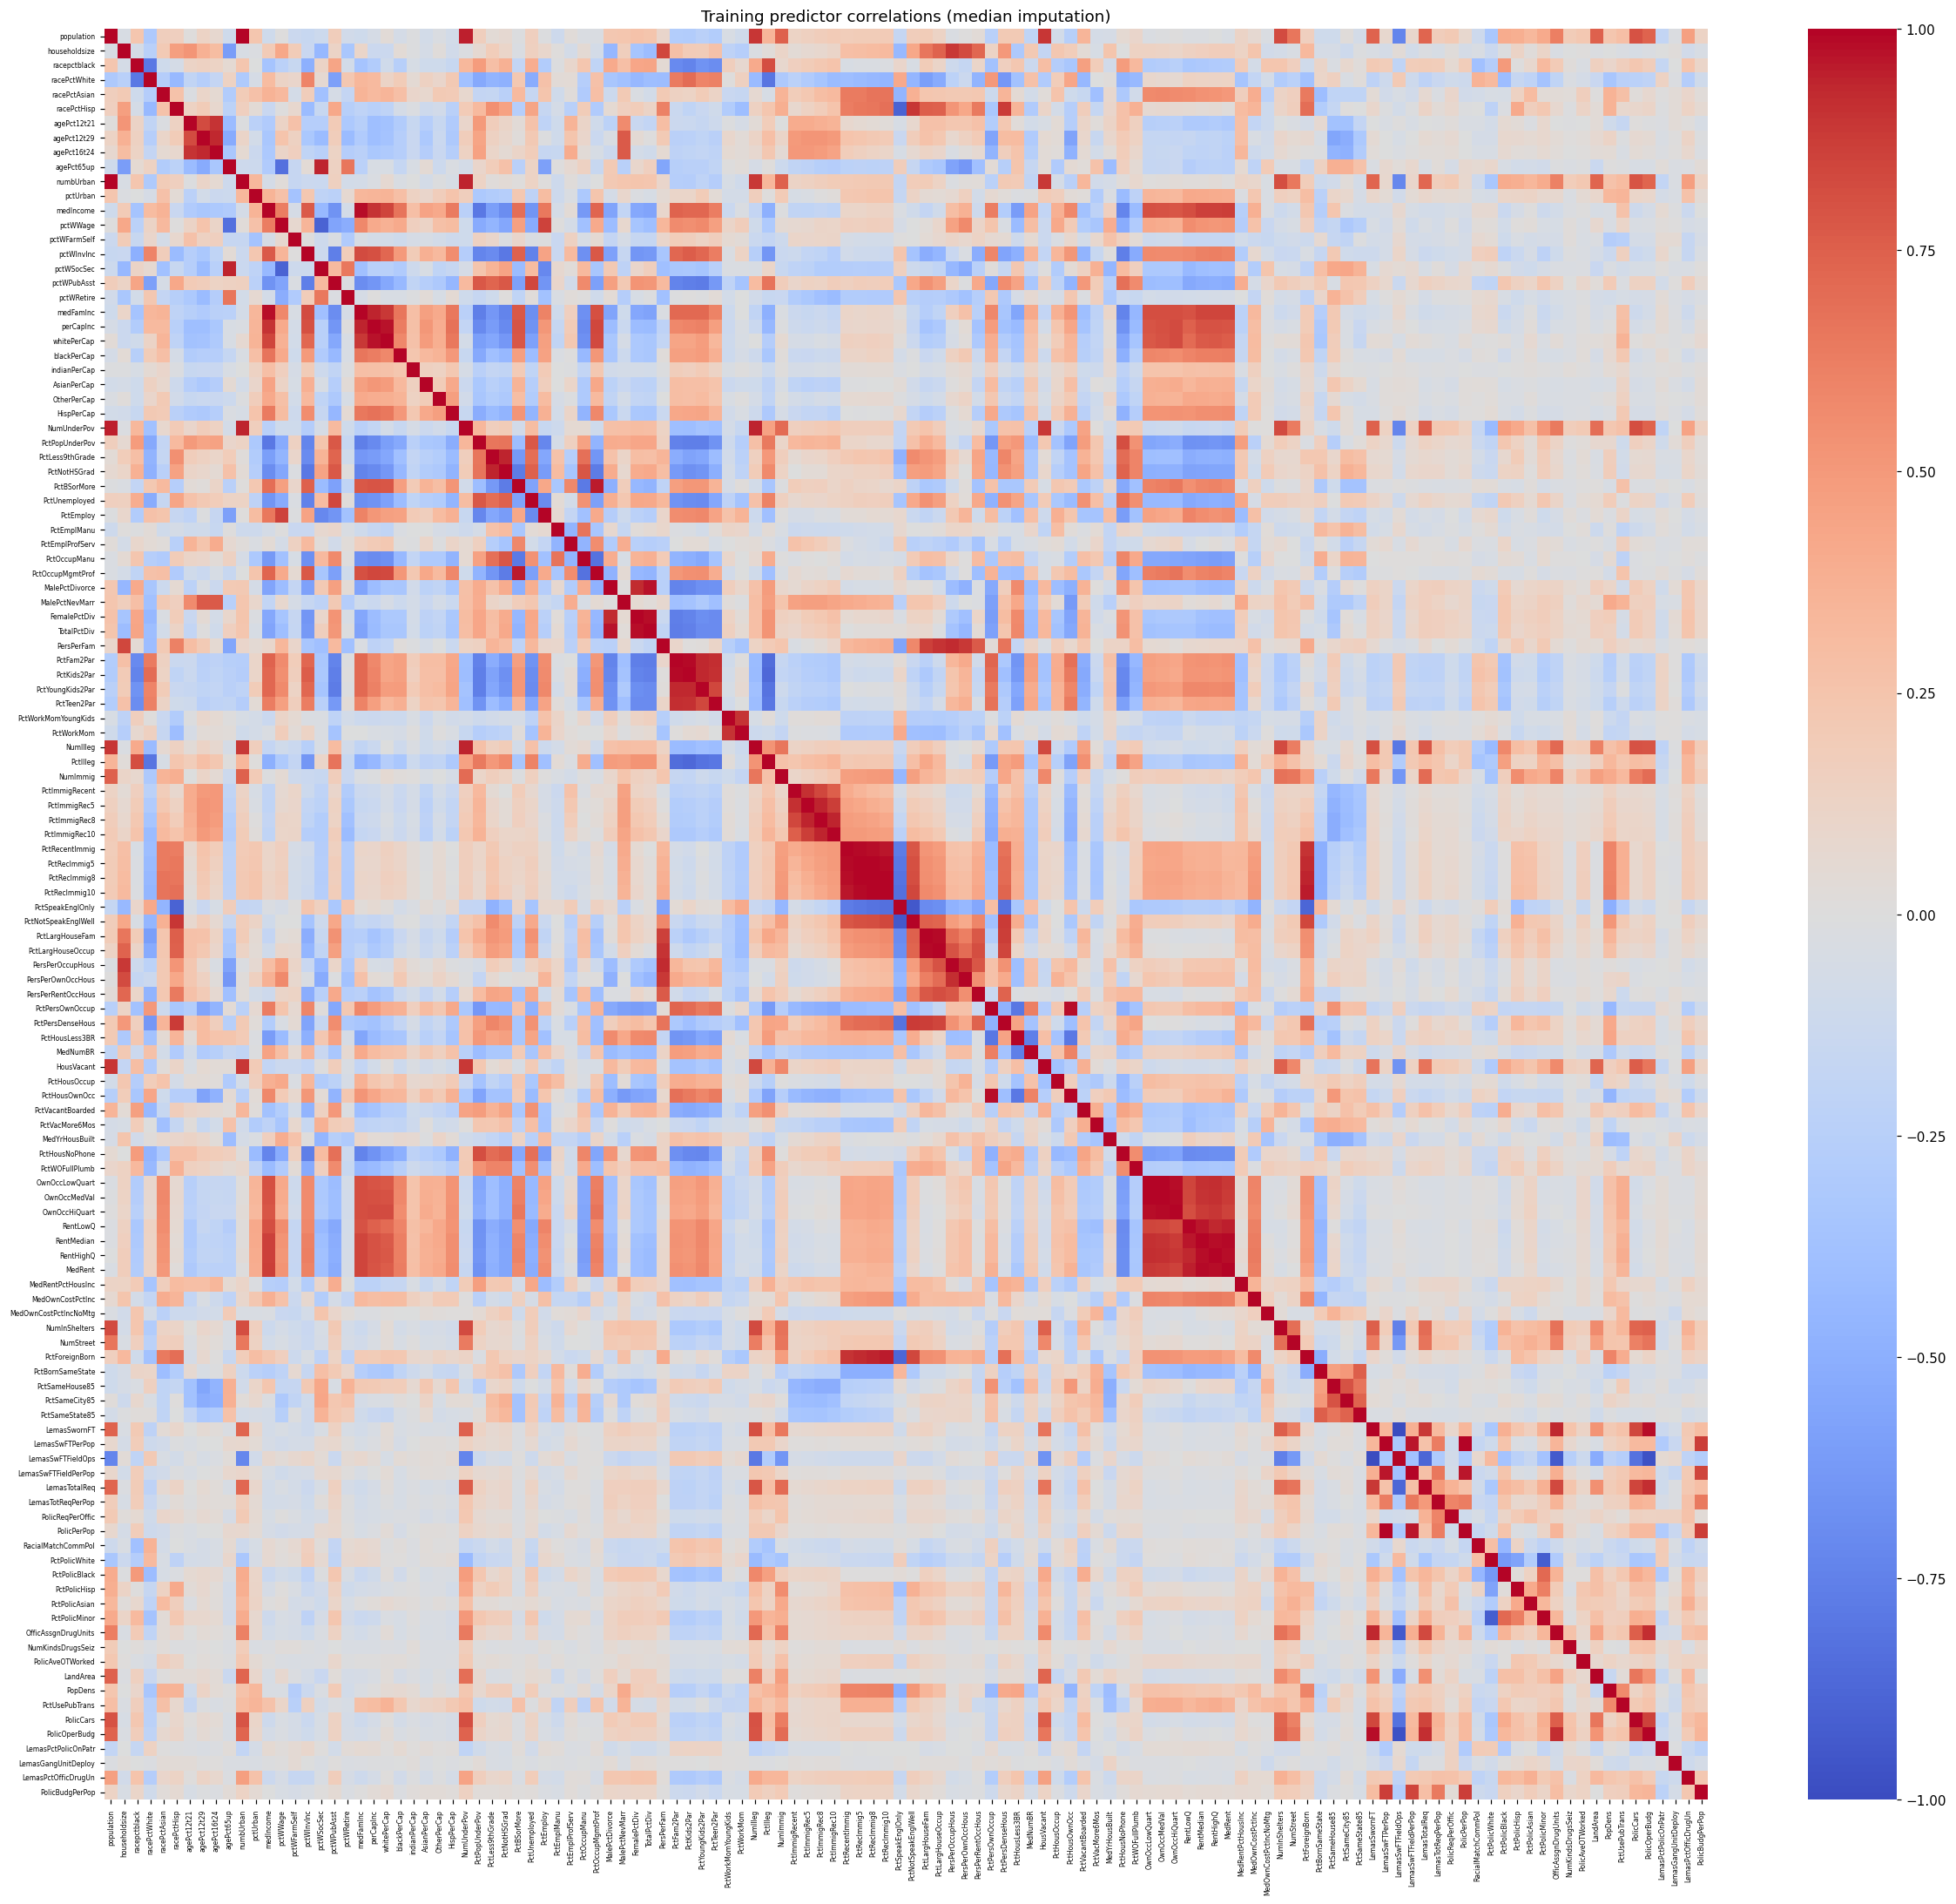

In [6]:
corr=Xeda.corr()
corr.to_csv('feature_correlations.csv')
plt.figure(figsize=(27,24)); sns.heatmap(corr,vmin=-1,vmax=1,cmap='coolwarm',xticklabels=True,yticklabels=True)
plt.xticks(fontsize=5); plt.yticks(fontsize=5); plt.title('Training predictor correlations (median imputation)')
finish('correlations.png')



### 2(d–e). Coefficients of Variation and Selected Features

For each predictor, I calculate the coefficient of variation:

$$
CV_j = \frac{s_j}{\bar{x}_j}
$$

where $s_j$ is the sample standard deviation and $\bar{x}_j$ is the sample mean, using the imputed training data.

I select the 11 features with the highest CV values ($\lfloor\sqrt{128}\rfloor = 11$) and generate scatter plots against the response variable and box plots for their distributions.

A high CV indicates greater variability relative to the mean, but does not necessarily imply predictive importance. **Statistical significance cannot be determined from scatter plots alone; formal statistical tests are required.**


                             CV
PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
PolicOperBudg          1.645508
LandArea               1.645408
racePctHisp            1.612091
PctNotSpeakEnglWell    1.456618
LemasTotalReq          1.451887
racepctblack           1.428885
PctUsePubTrans         1.397110
racePctAsian           1.359100
PctPolicHisp           1.353882
PctRecentImmig         1.288287
PctRecImmig5           1.286184
PctRecImmig10          1.270476
PctRecImmig8           1.265579
OfficAssgnDrugUnits    1.174565
PctPersDenseHous       1.132926
PolicCars              1.112831
PctForeignBorn         1.065880
PctVacantBoarded       1.054827
PctHousNoPhone         0.922765
PctIlleg

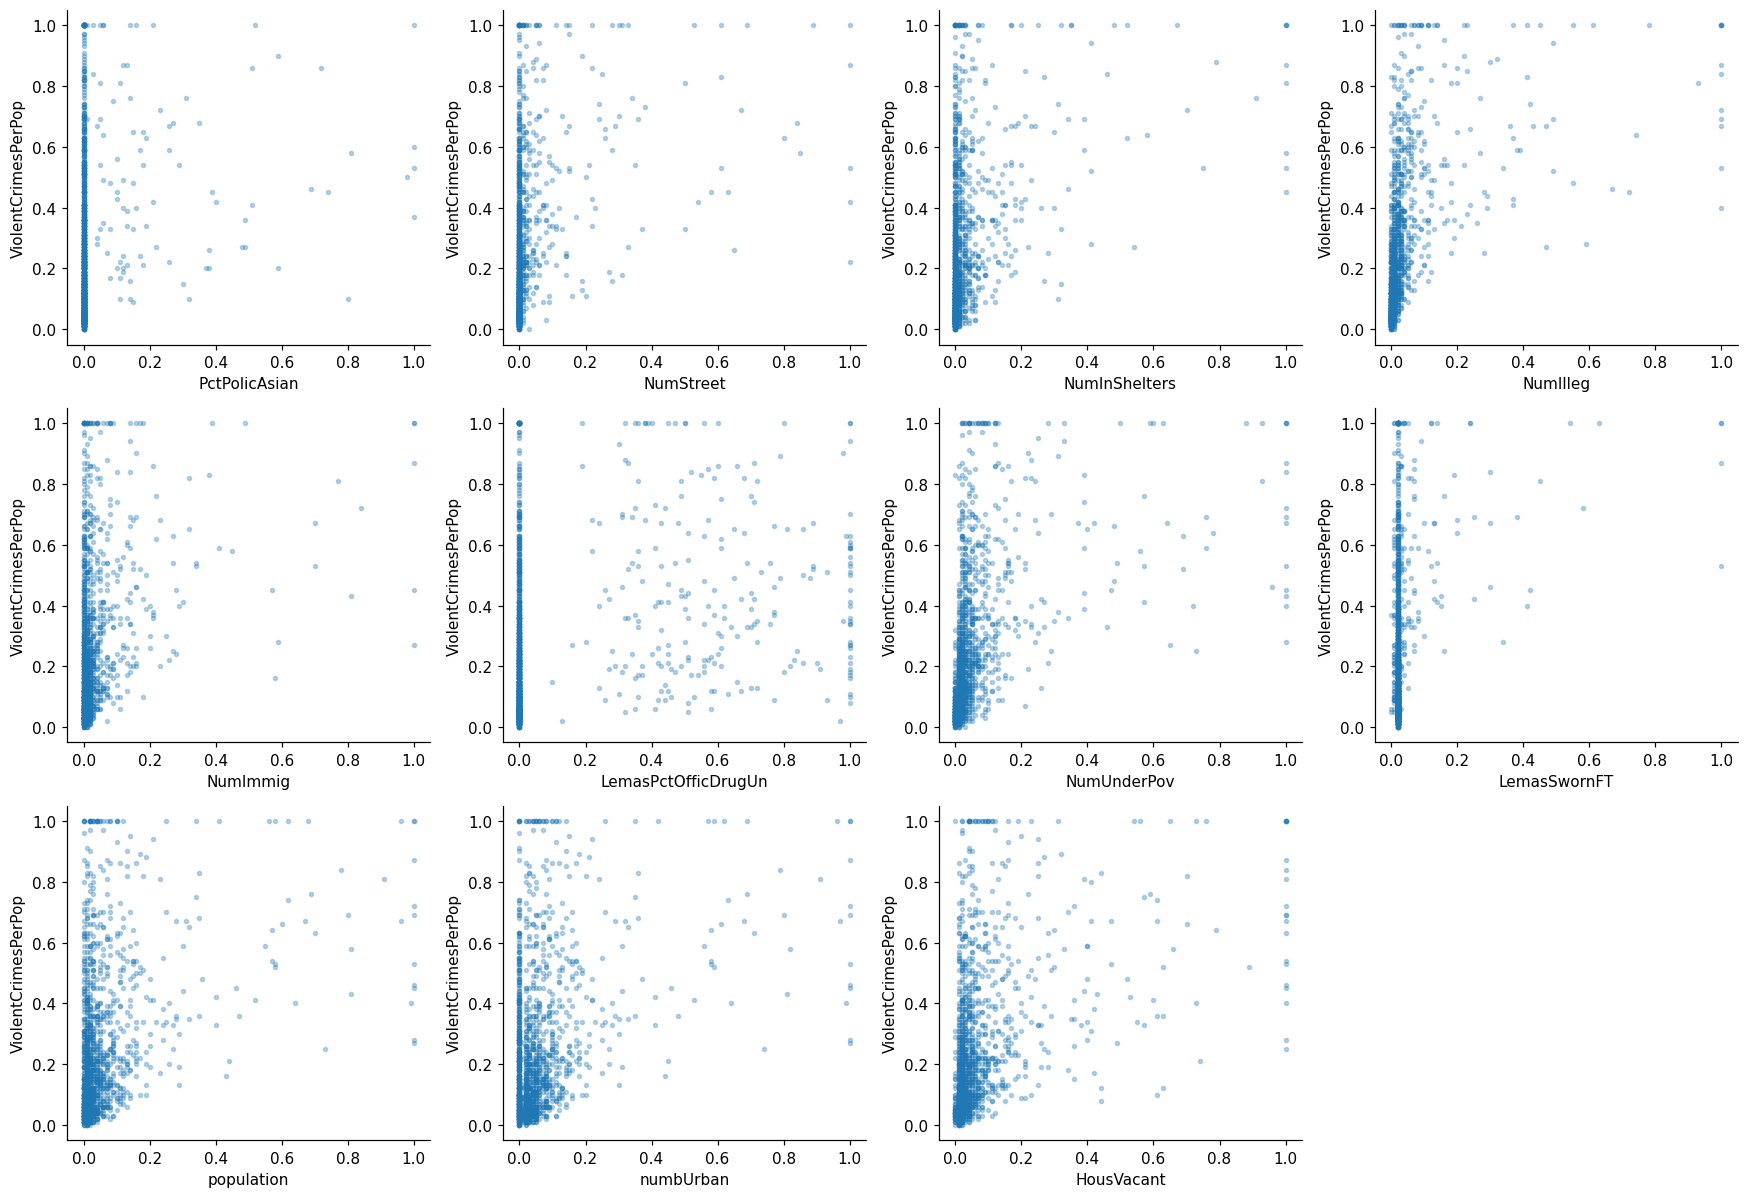

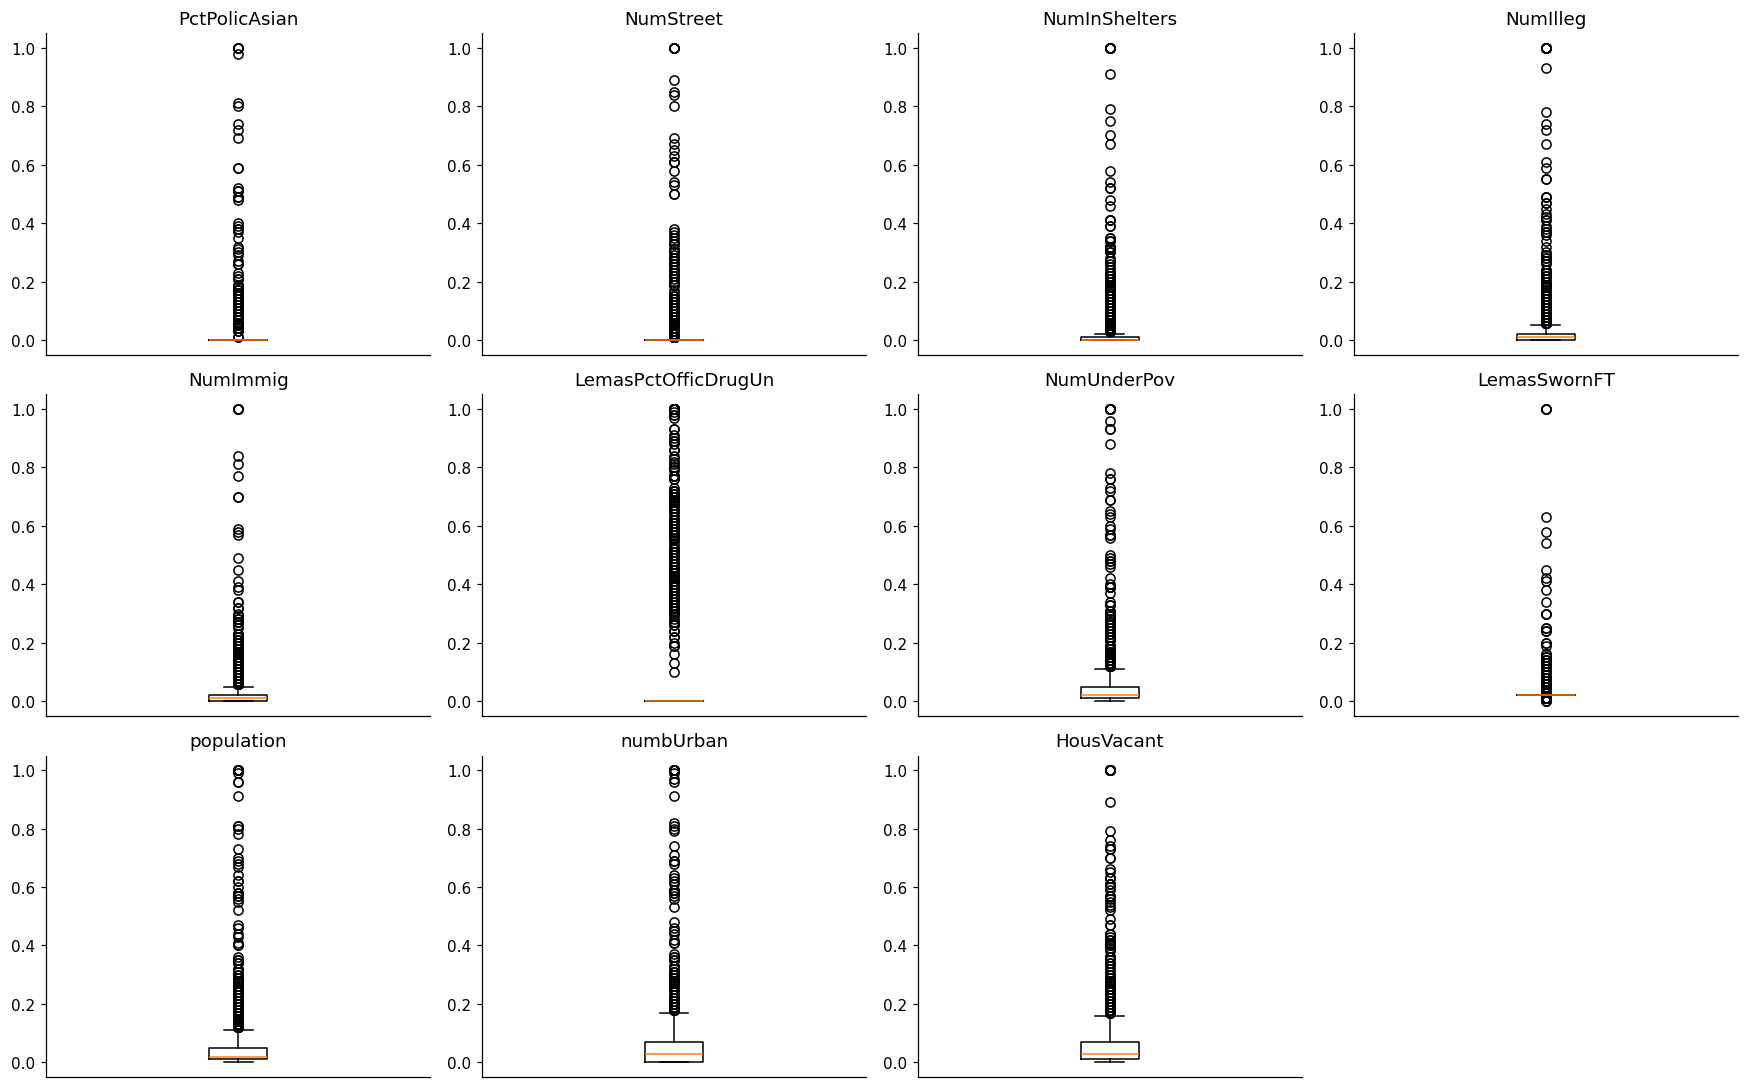

In [7]:
cv_features=(Xeda.std(ddof=1)/Xeda.mean().replace(0,np.nan)).sort_values(ascending=False)
cv_features.rename('CV').to_csv('feature_cv.csv')
print(cv_features.rename('CV').to_frame().to_string())
top=cv_features.head(int(np.sqrt(128))).index.tolist()
print('Selected 11:',', '.join(top))
fig,axes=plt.subplots(3,4,figsize=(16,11))
for ax,c in zip(axes.flat,top):
    ax.scatter(Xeda[c],ytr,s=7,alpha=.3); ax.set(xlabel=c,ylabel='ViolentCrimesPerPop')
axes.flat[-1].axis('off'); plt.tight_layout(); finish('top_cv_scatter.png')
fig,axes=plt.subplots(3,4,figsize=(16,10))
for ax,c in zip(axes.flat,top):
    ax.boxplot(Xeda[c],showfliers=True); ax.set(title=c); ax.set_xticks([])
axes.flat[-1].axis('off'); plt.tight_layout(); finish('top_cv_boxplots.png')


## 2(f–h). Least squares, ridge, and LASSO

**(f) Least Squares:**  
I fit a linear regression model using the training data and evaluate its test error using mean squared error (MSE).

**(g) Ridge Regression:**  
I fit a ridge regression model with standardized predictors. The regularization parameter $\lambda$ is selected using five-fold cross-validation to minimize validation MSE. I then report the test MSE.

**(h) LASSO:**  
I fit a LASSO model using five-fold cross-validation to select $\lambda$. I report the test MSE and the variables selected by the model (nonzero coefficients).

I repeat LASSO with standardized features and compare the test MSEs of the two models.


In [8]:
results=[]; searches={}; fitted={}
def evaluate(name,model,cv_mse=np.nan,choice='—'):
    pred=model.predict(Xte); mse=mean_squared_error(yte,pred)
    results.append({'model':name,'choice':choice,'CV_MSE':cv_mse,'test_MSE':mse,'test_RMSE':np.sqrt(mse)})
    fitted[name]=model
    print(name, '|',choice,'| test MSE:',f'{mse:.8f}')
def pipe(reg,scale=False):
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if scale: steps.append(('scale',StandardScaler()))
    return Pipeline(steps+[('model',reg)])
ols=pipe(LinearRegression()).fit(Xtr,ytr)
evaluate('Least squares',ols)
ridge=GridSearchCV(pipe(Ridge(),True),{'model__alpha':np.logspace(-5,5,61)},cv=folds,scoring='neg_mean_squared_error',n_jobs=1).fit(Xtr,ytr)
searches['Ridge']=ridge
evaluate('Ridge',ridge.best_estimator_,-ridge.best_score_,f"lambda={ridge.best_params_['model__alpha']:.8g}")
for label,scale in [('LASSO normalized',False),('LASSO standardized',True)]:
    gs=GridSearchCV(pipe(Lasso(max_iter=100000,tol=1e-6,precompute=True),scale),{'model__alpha':np.logspace(-6,-1,80)},cv=folds,scoring='neg_mean_squared_error',n_jobs=1).fit(Xtr,ytr)
    searches[label]=gs
    evaluate(label,gs.best_estimator_,-gs.best_score_,f"lambda={gs.best_params_['model__alpha']:.8g}")
    coef=gs.best_estimator_.named_steps['model'].coef_
    selected=pd.Series(coef,index=X.columns); selected=selected[selected!=0].sort_values()
    selected.to_csv(label.lower().replace(' ','_')+'_selected.csv')
    display(Markdown(f'**{label}: {len(selected)} selected variables** (nonzero coefficients).'))
    print(selected.to_string())


Least squares | — | test MSE: 0.01796622
Ridge | lambda=146.77993 | test MSE: 0.01735299
LASSO normalized | lambda=0.00010600258 | test MSE: 0.01764874


**LASSO normalized: 73 selected variables** (nonzero coefficients).

agePct12t29             -0.281653
PctKids2Par             -0.199595
RentLowQ                -0.163118
PctPopUnderPov          -0.145160
PctWorkMom              -0.132236
pctWRetire              -0.108979
pctWInvInc              -0.106788
NumImmig                -0.101160
NumIlleg                -0.098143
FemalePctDiv            -0.091501
pctWWage                -0.089057
PctNotSpeakEnglWell     -0.079666
MedOwnCostPctIncNoMtg   -0.079251
PctLargHouseOccup       -0.078135
PctPersOwnOccup         -0.063102
PctVacMore6Mos          -0.061740
PctHousOccup            -0.060771
whitePerCap             -0.059053
PctUsePubTrans          -0.045774
PctYoungKids2Par        -0.037371
NumKindsDrugsSeiz       -0.033780
indianPerCap            -0.031002
PctWOFullPlumb          -0.025351
RacialMatchCommPol      -0.023032
blackPerCap             -0.022485
PctLess9thGrade         -0.021175
OwnOccLowQuart          -0.017639
PctEmplManu             -0.017272
PctPolicBlack           -0.016987
racePctAsian  

**LASSO standardized: 75 selected variables** (nonzero coefficients).

agePct12t29             -0.044176
PctKids2Par             -0.040643
RentLowQ                -0.031406
PctPopUnderPov          -0.029855
PctWorkMom              -0.022561
pctWInvInc              -0.022338
pctWRetire              -0.017964
FemalePctDiv            -0.015349
MedOwnCostPctIncNoMtg   -0.014714
pctWWage                -0.014590
PctNotSpeakEnglWell     -0.013820
PctLargHouseOccup       -0.012908
PctPersOwnOccup         -0.011864
PctHousOccup            -0.011849
NumImmig                -0.011437
PctVacMore6Mos          -0.011159
NumIlleg                -0.010551
PctUsePubTrans          -0.009933
whitePerCap             -0.009757
PctYoungKids2Par        -0.007662
LemasTotalReq           -0.005556
indianPerCap            -0.005264
PctWOFullPlumb          -0.005214
blackPerCap             -0.003922
MedOwnCostPctInc        -0.003775
PctLess9thGrade         -0.003745
NumKindsDrugsSeiz       -0.003514
PctPolicBlack           -0.003345
RacialMatchCommPol      -0.003232
MedYrHousBuilt

### 2(i). Principal Component Regression (PCR)

I fit a PCR model using the training data. Imputation, standardization, and PCA are performed within five-fold cross-validation to avoid data leakage.

The number of principal components, $M$, is selected from 1 to 122 by minimizing the mean validation MSE. The final model is evaluated on the test set, and the test MSE is reported.


Selected M: 60
CV MSE: 0.020198
Test MSE: 0.018350
Test RMSE: 0.135460
Explained variance: 0.9806


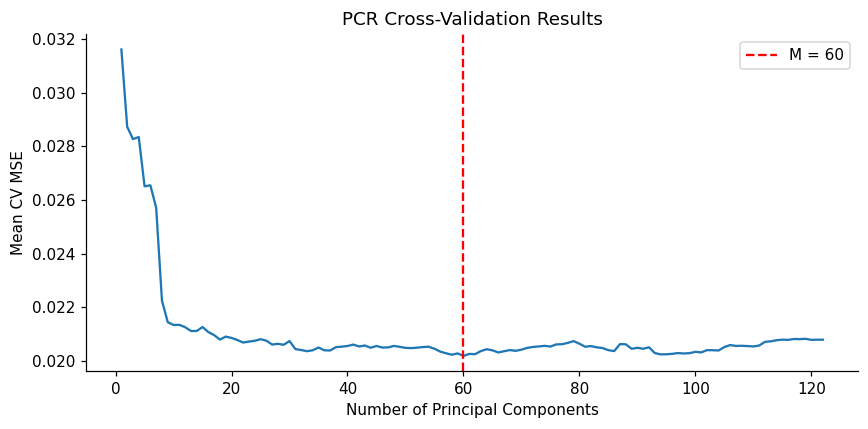

In [9]:
# Number of predictors
p = Xtr.shape[1]

# PCR pipeline
pcr_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('model', LinearRegression())
])

# Five-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pcr_cv = GridSearchCV(
    estimator=pcr_pipe,
    param_grid={'pca__n_components': list(range(1, p + 1))},
    scoring='neg_mean_squared_error',
    cv=cv,
    n_jobs=-1
)

# Fit PCR using training data
pcr_cv.fit(Xtr, ytr)

# Best number of principal components
M = pcr_cv.best_params_['pca__n_components']
pcr = pcr_cv.best_estimator_
cv_mse = -pcr_cv.best_score_

# Evaluate on test data
y_pred = pcr.predict(Xte)
test_mse = mean_squared_error(yte, y_pred)
test_rmse = np.sqrt(test_mse)

print(f"Selected M: {M}")
print(f"CV MSE: {cv_mse:.6f}")
print(f"Test MSE: {test_mse:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")

# Variance explained by selected components
variance_explained = (
    pcr.named_steps['pca']
    .explained_variance_ratio_.sum()
)
print(f"Explained variance: {variance_explained:.4f}")

# Add PCR results to the model comparison table
if 'results' not in globals():
    results = []

results = [
    r for r in results
    if r['model'] != 'PCR'
]

results.append({
    'model': 'PCR',
    'choice': f'M={M}',
    'CV_MSE': cv_mse,
    'test_MSE': test_mse,
    'test_RMSE': test_rmse
})

# Plot cross-validation MSE
mean_pcr = -pcr_cv.cv_results_['mean_test_score']
components = np.arange(1, p + 1)

plt.figure(figsize=(8, 4))
plt.plot(components, mean_pcr)
plt.axvline(
    M,
    color='red',
    linestyle='--',
    label=f'M = {M}'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Mean CV MSE')
plt.title('PCR Cross-Validation Results')
plt.legend()
plt.tight_layout()
plt.show()


### 2(j). L1-Regularized Gradient Boosting with XGBoost

I fit an XGBoost regression tree model with L1 regularization on leaf weights. The regularization parameter $\alpha$ (`reg_alpha`) is selected using five-fold cross-validation to minimize validation MSE. The final model is evaluated on the test set.

In [10]:
boost=GridSearchCV(pipe(XGBRegressor(n_estimators=500,max_depth=3,learning_rate=.05,subsample=1,colsample_bytree=1,reg_lambda=1,objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=SEED)),{'model__reg_alpha':[0,.001,.01,.1,1,10,100]},cv=folds,scoring='neg_mean_squared_error',n_jobs=1).fit(Xtr,ytr)
searches['XGBoost']=boost
evaluate('XGBoost',boost.best_estimator_,-boost.best_score_,f"alpha={boost.best_params_['model__reg_alpha']}")
display(pd.DataFrame({'alpha':boost.cv_results_['param_model__reg_alpha'],'CV_MSE':-boost.cv_results_['mean_test_score']}))


XGBoost | alpha=0.1 | test MSE: 0.01642875


,alpha,CV_MSE
0,0.000,0.020463
1,0.001,0.020282
2,0.010,0.020185
3,0.100,0.019942
4,1.000,0.020359
5,10.000,0.021958
6,100.000,0.056606



### Results and Comparison

The table summarizes the test MSEs of all models in 2(f–j).

I compare the test MSEs to evaluate their predictive performance and examine the effect of standardization on LASSO.


,model,choice,CV_MSE,test_MSE,test_RMSE
0,Least squares,—,nan,0.0179662,0.1340381
1,Ridge,lambda=146.77993,0.0197373,0.0173530,0.1317308
2,LASSO normalized,lambda=0.00010600258,0.0195181,0.0176487,0.1328485
3,LASSO standardized,lambda=0.00060927047,0.0196612,0.0177293,0.1331513
4,PCR,M=60,0.0201976,0.0183495,0.1354604
5,XGBoost,alpha=0.1,0.0199425,0.0164288,0.1281747


Standardized LASSO has **higher** test MSE (0.0177293) than LASSO on the supplied normalized predictors (0.0176487). Scaling changes the selected penalty and selected variables. The feature lists above are predictive selections, not tests of statistical significance.

The smallest observed test MSE is **0.0164288**, from **XGBoost**. This ranking is specific to the mandated split; it is not evidence that the method is universally superior. Crime-related associations at community level do not establish individual-level or causal relationships.

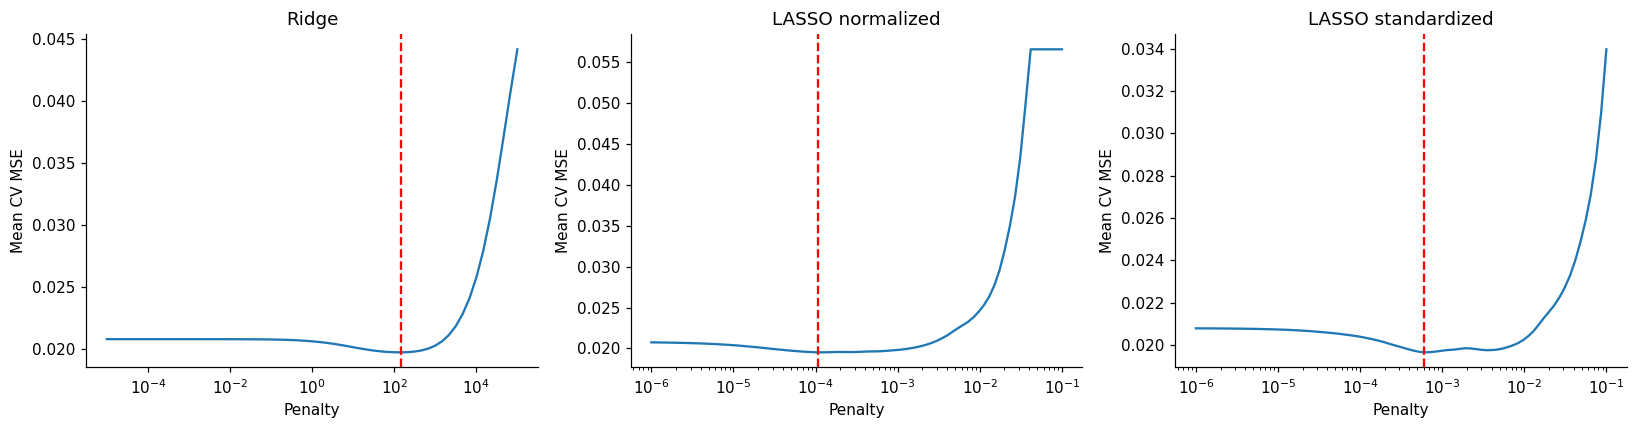

All penalty optima are interior to their search grids.
All dimensions and result checks passed.


In [11]:
summary=pd.DataFrame(results)
summary.to_csv('model_results.csv',index=False)
display(summary.style.format({'CV_MSE':'{:.7f}','test_MSE':'{:.7f}','test_RMSE':'{:.7f}'}))
a=summary.set_index('model')
raw=a.loc['LASSO normalized','test_MSE']; std=a.loc['LASSO standardized','test_MSE']
comparison='lower' if std<raw else 'higher'
display(Markdown(f"Standardized LASSO has **{comparison}** test MSE ({std:.7f}) than LASSO on the supplied normalized predictors ({raw:.7f}). Scaling changes the selected penalty and selected variables. The feature lists above are predictive selections, not tests of statistical significance."))
winner=summary.loc[summary.test_MSE.idxmin()]
display(Markdown(f"The smallest observed test MSE is **{winner.test_MSE:.7f}**, from **{winner['model']}**. This ranking is specific to the mandated split; it is not evidence that the method is universally superior. Crime-related associations at community level do not establish individual-level or causal relationships."))
# Show tuning curves and check grid boundaries.
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,label in zip(axes,['Ridge','LASSO normalized','LASSO standardized']):
    gs=searches[label]; xx=np.array(gs.cv_results_['param_model__alpha'],dtype=float)
    ax.semilogx(xx,-gs.cv_results_['mean_test_score']); ax.axvline(gs.best_params_['model__alpha'],color='red',linestyle='--')
    ax.set(title=label,xlabel='Penalty',ylabel='Mean CV MSE')
    assert gs.best_params_['model__alpha'] not in (xx.min(),xx.max()), 'Expand penalty grid'
plt.tight_layout(); finish('regularization_cv.png')
print('All penalty optima are interior to their search grids.')
assert len(top)==11 and summary.shape[0]==6 and np.isfinite(summary.test_MSE).all()
print('All dimensions and result checks passed.')
